In [1]:
import time
import numpy as np
from IPython.display import Markdown, display

from ifm_konwoledge_enginnering.Block_World.Project.src.World import World
from ifm_konwoledge_enginnering.Block_World.Project.src.search_path.bfs import bfs_with_stats
from ifm_konwoledge_enginnering.Block_World.Project.src.search_path.dfs import dfs_with_stats
from ifm_konwoledge_enginnering.Block_World.Project.src.utils.state_generator import start_goal_generator
from ifm_konwoledge_enginnering.Block_World.Project.src.utils.path_utils import check_path

DEFAULT_SEED = 42
BLOCK_COUNTS = range(3, 9)
MAX_EXPANDED = 400_000
EXTENDED_MOVES = True


In [2]:
def run_search(algorithm, search_fn, start, goal, n_blocks, seed=DEFAULT_SEED):
    """Run one search and return comparable metrics and its path."""
    wall_start = time.perf_counter()
    try:
        result = search_fn(
            start,
            goal,
            max_visited_notes=MAX_EXPANDED,
            extended=EXTENDED_MOVES,
        )
    except RuntimeError as error:
        return {
            "algorithm": algorithm,
            "blocks": n_blocks,
            "seed": seed,
            "status": f"limit / failure: {error}",
            "path_length": None,
            "expanded_nodes": getattr(error, "expanded", f">={MAX_EXPANDED}"),
            "peak_stored_states": getattr(error, "peak_stored_states", None),
            "time_seconds": getattr(error, "elapsed", time.perf_counter() - wall_start),
            "path": None,
        }

    # check_path validates the moves and leaves the resulting placement on this copy.
    current = World(start.placement.copy())
    valid_moves = check_path(current, result.path)
    valid = valid_moves and np.array_equal(current.placement, goal.placement)

    return {
        "algorithm": algorithm,
        "blocks": n_blocks,
        "seed": seed,
        "status": "valid" if valid else "INVALID PATH",
        "path_length": len(result.path),
        "expanded_nodes": result.expanded,
        "peak_stored_states": result.peak_stored_states,
        "time_seconds": result.elapsed,
        "path": result.path,
    }

def show_result(result, show_path=False):
    print("=" * 48)
    print(f"{result['algorithm']} | blocks={result['blocks']} | seed={result['seed']}")
    print(f"Status: {result['status']}")
    print(f"Path length: {result['path_length']}")
    print(f"Expanded nodes: {result['expanded_nodes']}")
    print(f"Time: {result['time_seconds']:.6f} seconds")
    if show_path and result["path"] is not None:
        print("Moves are shown as (block moved, destination); 0 means table.")
        for move in result["path"]:
            print(f"({move.moving}, {move.destination})")

def display_table(records, columns):
    def format_value(value):
        if isinstance(value, float):
            return f"{value:.6f}"
        return str(value)

    header = "| " + " | ".join(columns) + " |"
    divider = "| " + " | ".join("---" for _ in columns) + " |"
    rows = [
        "| " + " | ".join(format_value(record[column]) for column in columns) + " |"
        for record in records
    ]
    display(Markdown("\n".join([header, divider, *rows])))


## Example: both algorithms on the same problem

The generator uses seed 42 by default. Both searches receive the same start and goal.

In [3]:
example_n = 4
example = start_goal_generator(example_n)
print(f"Start: {example.start.placement}")
print(f"Goal:  {example.goal.placement}")

example_results = [
    run_search("DFS", dfs_with_stats, example.start, example.goal, example_n),
    run_search("BFS", bfs_with_stats, example.start, example.goal, example_n),
]
for result in example_results:
    show_result(result, show_path=True)


Start: [0 3 4 0]
Goal:  [4 0 0 3]
DFS | blocks=4 | seed=42
Status: valid
Path length: 4
Expanded nodes: 15
Time: 0.009332 seconds
Moves are shown as (block moved, destination); 0 means table.
(2, 0)
(3, 0)
(4, 3)
(1, 4)
BFS | blocks=4 | seed=42
Status: valid
Path length: 4
Expanded nodes: 13
Time: 0.009863 seconds
Moves are shown as (block moved, destination); 0 means table.
(2, 0)
(3, 0)
(4, 3)
(1, 4)


## Paired comparison by block count

Each block count gets one reproducible start/goal pair (default seed 42); DFS and BFS solve that same pair. The expansion cap keeps BFS runs bounded. A capped run is marked as a limit/failure and is not counted as a completed path.

In [4]:
results = []
for n_blocks in BLOCK_COUNTS:
    problem = start_goal_generator(n_blocks)  # seed defaults to 42
    print(f"Running {n_blocks} blocks; start={problem.start.placement}, goal={problem.goal.placement}")
    results.append(run_search("DFS", dfs_with_stats, problem.start, problem.goal, n_blocks))
    results.append(run_search("BFS", bfs_with_stats, problem.start, problem.goal, n_blocks))

display_table(
    results,
    ["blocks", "seed", "algorithm", "status", "path_length", "expanded_nodes", "time_seconds"],
)


Running 3 blocks; start=[2 3 0], goal=[0 1 0]
Running 4 blocks; start=[0 3 4 0], goal=[4 0 0 3]
Running 5 blocks; start=[2 0 5 3 0], goal=[5 4 0 1 0]
Running 6 blocks; start=[2 5 4 0 6 0], goal=[6 5 1 0 0 0]
Running 7 blocks; start=[0 5 4 0 7 2 0], goal=[5 0 1 0 0 4 2]
Running 8 blocks; start=[6 0 5 0 0 2 8 3], goal=[6 4 5 3 0 0 8 2]


| blocks | seed | algorithm | status | path_length | expanded_nodes | time_seconds |
| --- | --- | --- | --- | --- | --- | --- |
| 3 | 42 | DFS | valid | 2 | 2 | 0.000742 |
| 3 | 42 | BFS | valid | 2 | 2 | 0.000379 |
| 4 | 42 | DFS | valid | 4 | 15 | 0.008781 |
| 4 | 42 | BFS | valid | 4 | 13 | 0.009577 |
| 5 | 42 | DFS | valid | 38 | 67 | 0.055707 |
| 5 | 42 | BFS | valid | 5 | 138 | 0.150085 |
| 6 | 42 | DFS | valid | 8 | 10 | 0.018806 |
| 6 | 42 | BFS | valid | 6 | 328 | 0.529700 |
| 7 | 42 | DFS | valid | 8 | 8 | 0.020234 |
| 7 | 42 | BFS | valid | 7 | 4742 | 9.181142 |
| 8 | 42 | DFS | valid | 22 | 22 | 0.080383 |
| 8 | 42 | BFS | valid | 9 | 81686 | 184.815304 |

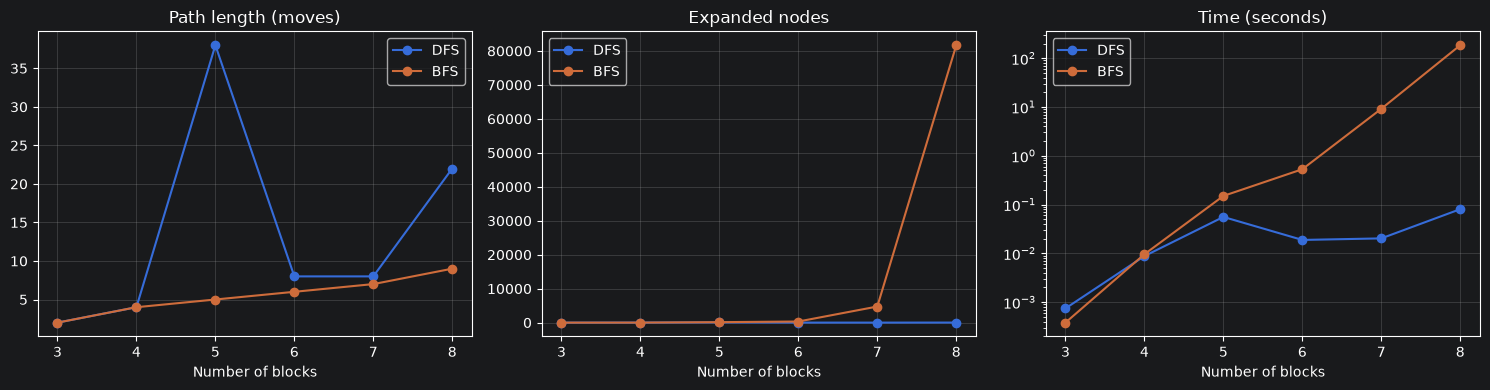

In [5]:
completed = [row for row in results if row["status"] == "valid"]
if not completed:
    print("No completed runs to plot.")
else:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("Install matplotlib to display comparison plots; the results table is still available.")
    else:
        metrics = [
            ("path_length", "Path length (moves)"),
            ("expanded_nodes", "Expanded nodes"),
            ("time_seconds", "Time (seconds)"),
        ]
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for axis, (metric, title) in zip(axes, metrics):
            for algorithm in ("DFS", "BFS"):
                selected = sorted(
                    (row for row in completed if row["algorithm"] == algorithm),
                    key=lambda row: row["blocks"],
                )
                axis.plot(
                    [row["blocks"] for row in selected],
                    [row[metric] for row in selected],
                    marker="o",
                    label=algorithm,
                )
            axis.set_title(title)
            axis.set_xlabel("Number of blocks")
            axis.grid(True, alpha=0.3)
            axis.legend()
        axes[2].set_yscale("log")
        fig.tight_layout()
        plt.show()


## Reading the results

Compare path length, expanded nodes, and elapsed search time for each matched problem. BFS should produce a shortest path for this unit-cost search; DFS may find a longer path. Timing is machine-dependent, while path validity and length are reproducible for the fixed inputs and move ordering. The expansion cap means a limited run has no path-length result.

# n = 8 blocks

In [6]:
def compare_last_n8_run(seeds=range(10)):
    """Run paired DFS/BFS trials and return per-seed metrics plus averages.

    peak_stored_states counts unique discovered states retained in the visited set.
    """
    n_blocks = 8
    run_results = []
    for seed in seeds:
        problem = start_goal_generator(n_blocks=n_blocks, seed=seed)
        print(f"Running N=8 with seed={seed}; start={problem.start.placement}, goal={problem.goal.placement}")
        run_results.append(run_search("DFS", dfs_with_stats, problem.start, problem.goal, n_blocks, seed))
        run_results.append(run_search("BFS", bfs_with_stats, problem.start, problem.goal, n_blocks, seed))

    metrics = ["path_length", "expanded_nodes", "peak_stored_states", "time_seconds"]
    display_table(
        run_results,
        ["blocks", "seed", "algorithm", "status", *metrics],
    )

    averages = []
    for algorithm in ("DFS", "BFS"):
        completed = [row for row in run_results if row["algorithm"] == algorithm and row["status"] == "valid"]
        averages.append({"blocks": n_blocks, "seed": "mean", "algorithm": algorithm, "status": f"mean ({len(completed)}/10 valid)", **{metric: (sum(row[metric] for row in completed) / len(completed) if completed else None) for metric in metrics}})
    print("Averages for completed runs (peak stored states = unique states retained in visited):")
    display_table(averages, ["blocks", "seed", "algorithm", "status", *metrics])
    return run_results, averages

n8_results, n8_averages = compare_last_n8_run()


Running N=8 with seed=0; start=[6 1 0 5 3 7 4 2], goal=[8 0 5 2 6 0 0 0]
Running N=8 with seed=1; start=[6 1 5 7 2 0 0 4], goal=[3 0 0 0 6 0 8 0]
Running N=8 with seed=2; start=[5 1 0 0 0 7 0 6], goal=[6 0 2 8 1 4 0 0]
Running N=8 with seed=3; start=[4 0 8 6 2 0 0 7], goal=[0 0 0 6 4 0 0 2]
Running N=8 with seed=4; start=[3 0 2 6 0 5 4 1], goal=[0 0 8 3 2 5 6 1]
Running N=8 with seed=5; start=[7 0 5 3 0 0 6 0], goal=[4 3 0 5 2 0 8 0]
Running N=8 with seed=6; start=[0 0 0 6 1 0 2 0], goal=[0 0 7 0 1 0 4 3]
Running N=8 with seed=7; start=[0 6 0 0 3 5 0 7], goal=[7 5 0 8 4 0 2 0]
Running N=8 with seed=8; start=[8 0 2 0 0 1 6 4], goal=[7 5 0 1 0 8 2 0]
Running N=8 with seed=9; start=[0 7 6 0 3 8 1 4], goal=[3 5 0 8 0 7 0 0]


| blocks | seed | algorithm | status | path_length | expanded_nodes | peak_stored_states | time_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 8 | 0 | DFS | valid | 8 | 8 | 79 | 0.022122 |
| 8 | 0 | BFS | valid | 8 | 618 | 2949 | 1.567497 |
| 8 | 1 | DFS | valid | 8 | 8 | 118 | 0.027049 |
| 8 | 1 | BFS | valid | 8 | 7736 | 30221 | 19.313267 |
| 8 | 2 | DFS | valid | 19 | 19 | 266 | 0.071652 |
| 8 | 2 | BFS | valid | 7 | 18863 | 65325 | 50.863053 |
| 8 | 3 | DFS | valid | 4 | 4 | 56 | 0.021637 |
| 8 | 3 | BFS | valid | 4 | 71 | 423 | 0.177527 |
| 8 | 4 | DFS | valid | 65 | 65 | 769 | 0.209182 |
| 8 | 4 | BFS | valid | 10 | 157510 | 269565 | 318.396668 |
| 8 | 5 | DFS | valid | 11 | 11 | 196 | 0.044755 |
| 8 | 5 | BFS | valid | 7 | 44806 | 127606 | 115.695187 |
| 8 | 6 | DFS | valid | 55 | 63 | 767 | 0.187573 |
| 8 | 6 | BFS | valid | 4 | 334 | 2716 | 1.224223 |
| 8 | 7 | DFS | valid | 64 | 70 | 809 | 0.208472 |
| 8 | 7 | BFS | valid | 8 | 62323 | 153731 | 149.450356 |
| 8 | 8 | DFS | valid | 8 | 8 | 76 | 0.019873 |
| 8 | 8 | BFS | valid | 8 | 21584 | 71405 | 57.081636 |
| 8 | 9 | DFS | valid | 8 | 8 | 91 | 0.021458 |
| 8 | 9 | BFS | valid | 8 | 7736 | 30221 | 19.033121 |

Averages for completed runs (peak stored states = unique states retained in visited):


| blocks | seed | algorithm | status | path_length | expanded_nodes | peak_stored_states | time_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 8 | mean | DFS | mean (10/10 valid) | 25.000000 | 26.400000 | 322.700000 | 0.083377 |
| 8 | mean | BFS | mean (10/10 valid) | 7.200000 | 32158.100000 | 75416.200000 | 73.280253 |